In [3]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: scikit-learn in c:\python310\lib\site-packages (1.7.2)




[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

1. Data Gathering


In [7]:
df=pd.read_csv("International_Education_Costs.csv")

In [8]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92


2. Data Exploration


df.describe()


In [9]:
df.describe()

,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
count,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000
mean,2.836825,16705.016538,64.437486,969.206174,211.396913,700.077178,623.000695
std,0.945449,16582.385275,14.056333,517.154752,143.435740,320.374875,3801.746134
min,1.000000,0.000000,27.800000,150.000000,40.000000,200.000000,0.150000
25%,2.000000,2850.000000,56.300000,545.000000,100.000000,450.000000,0.920000
50%,3.000000,7500.000000,67.500000,900.000000,160.000000,650.000000,1.350000
75%,4.000000,31100.000000,72.200000,1300.000000,240.000000,800.000000,7.150000
max,5.000000,62000.000000,122.400000,2500.000000,490.000000,1500.000000,42150.000000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    object 
 1   City               907 non-null    object 
 2   University         907 non-null    object 
 3   Program            907 non-null    object 
 4   Level              907 non-null    object 
 5   Duration_Years     907 non-null    float64
 6   Tuition_USD        907 non-null    int64  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int64  
 9   Visa_Fee_USD       907 non-null    int64  
 10  Insurance_USD      907 non-null    int64  
 11  Exchange_Rate      907 non-null    float64
dtypes: float64(3), int64(4), object(5)
memory usage: 85.2+ KB


In [11]:
df.shape

(907, 12)

In [12]:
df.size

10884

In [13]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float64
Tuition_USD            int64
Living_Cost_Index    float64
Rent_USD               int64
Visa_Fee_USD           int64
Insurance_USD          int64
Exchange_Rate        float64
dtype: object

In [14]:
df['Country'].unique()

array(['USA', 'UK', 'Canada', 'Australia', 'Germany', 'Japan',
       'Netherlands', 'Singapore', 'France', 'Switzerland', 'Sweden',
       'Denmark', 'China', 'South Korea', 'Ireland', 'New Zealand',
       'Austria', 'Belgium', 'Hong Kong', 'Portugal', 'Israel', 'Taiwan',
       'Czech Republic', 'India', 'Poland', 'Malaysia', 'Spain', 'Italy',
       'Finland', 'Norway', 'Brazil', 'Turkey', 'Russia', 'Mexico',
       'Greece', 'Thailand', 'UAE', 'South Africa', 'Egypt', 'Argentina',
       'Indonesia', 'Saudi Arabia', 'Nigeria', 'Vietnam', 'Hungary',
       'Iceland', 'Colombia', 'Romania', 'Luxembourg', 'Tunisia',
       'Cyprus', 'Croatia', 'Dominican Republic', 'Morocco', 'Peru',
       'Ecuador', 'Lebanon', 'Bahrain', 'Uruguay', 'Bulgaria', 'Ghana',
       'Algeria', 'Panama', 'Bangladesh', 'Kuwait', 'Ukraine', 'Slovenia',
       'Serbia', 'Iran', 'Uzbekistan', 'El Salvador'], dtype=object)

In [15]:
df[df['Country'] == 'India']

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
44,India,Bangalore,Indian Institute of Science,Computer Science,Master,2.0,2500,45.6,500,200,300,83.20
648,India,Bangalore,Indian Institute of Science,Data Science,PhD,4.0,2000,45.2,300,180,300,82.75
654,India,Mumbai,IIT Bombay,Computer Engineering,Master,2.0,1800,47.5,350,180,300,82.75
659,India,Delhi,IIT Delhi,Artificial Intelligence,PhD,4.0,1900,44.8,320,180,300,82.75
665,India,Chennai,IIT Madras,Software Engineering,Master,2.0,1700,42.4,280,180,300,82.75
671,India,Hyderabad,IIT Hyderabad,Data Analytics,PhD,4.0,1800,41.2,260,180,300,82.75
677,India,Pune,IIT Pune,Computer Science,Master,2.0,1600,40.5,250,180,300,82.75
683,India,Kanpur,IIT Kanpur,Artificial Intelligence,PhD,4.0,1900,39.8,240,180,300,82.75


3. Pre-Procesing data


In [16]:
df['Country'].value_counts()

Country
UK                93
Australia         86
USA               78
Canada            76
Germany           33
                  ..
Czech Republic     1
Hong Kong          1
Israel             1
Nigeria            1
Vietnam            1
Name: count, Length: 71, dtype: int64

In [17]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='object')

In [18]:
df.isnull()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
902,False,False,False,False,False,False,False,False,False,False,False,False
903,False,False,False,False,False,False,False,False,False,False,False,False
904,False,False,False,False,False,False,False,False,False,False,False,False
905,False,False,False,False,False,False,False,False,False,False,False,False


In [19]:
df.isnull().sum()

Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Tuition_USD          0
Living_Cost_Index    0
Rent_USD             0
Visa_Fee_USD         0
Insurance_USD        0
Exchange_Rate        0
dtype: int64

In [20]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
902    False
903    False
904    False
905    False
906    False
Length: 907, dtype: bool

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.shape

(907, 12)

In [23]:
df

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92
...,...,...,...,...,...,...,...,...,...,...,...,...
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,4000,70.2,1000,99,850,0.92
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,6800,50.5,400,120,400,4.65
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,4200,64.2,600,200,800,3.75
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,50000,77.8,2000,160,1500,1.00


In [24]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float64
Tuition_USD            int64
Living_Cost_Index    float64
Rent_USD               int64
Visa_Fee_USD           int64
Insurance_USD          int64
Exchange_Rate        float64
dtype: object

In [25]:
df['Duration_Years'] = df['Duration_Years'].astype('float32')

In [26]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float32
Tuition_USD            int64
Living_Cost_Index    float64
Rent_USD               int64
Visa_Fee_USD           int64
Insurance_USD          int64
Exchange_Rate        float64
dtype: object

In [27]:
df['Tuition_USD'] = df['Tuition_USD'].astype('int32')

In [28]:
df['Rent_USD'] = df['Rent_USD'].astype('int32')
df['Visa_Fee_USD'] = df['Visa_Fee_USD'].astype('int32')
df['Insurance_USD'] = df['Insurance_USD'].astype('int32')
df['Exchange_Rate'] = df['Exchange_Rate'].astype('float32')

In [29]:
df

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92
...,...,...,...,...,...,...,...,...,...,...,...,...
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,4000,70.2,1000,99,850,0.92
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,6800,50.5,400,120,400,4.65
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,4200,64.2,600,200,800,3.75
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,50000,77.8,2000,160,1500,1.00


In [30]:
df.dtypes

Country               object
City                  object
University            object
Program               object
Level                 object
Duration_Years       float32
Tuition_USD            int32
Living_Cost_Index    float64
Rent_USD               int32
Visa_Fee_USD           int32
Insurance_USD          int32
Exchange_Rate        float32
dtype: object

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    object 
 1   City               907 non-null    object 
 2   University         907 non-null    object 
 3   Program            907 non-null    object 
 4   Level              907 non-null    object 
 5   Duration_Years     907 non-null    float32
 6   Tuition_USD        907 non-null    int32  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int32  
 9   Visa_Fee_USD       907 non-null    int32  
 10  Insurance_USD      907 non-null    int32  
 11  Exchange_Rate      907 non-null    float32
dtypes: float32(2), float64(1), int32(4), object(5)
memory usage: 63.9+ KB


4. Exploratory Data Analysic


In [32]:
# univariant or BiVariant data analysis

In [33]:
df['Country'].value_counts().head(10)

Country
UK             93
Australia      86
USA            78
Canada         76
Germany        33
France         27
South Korea    23
Netherlands    21
Switzerland    20
Singapore      18
Name: count, dtype: int64

In [34]:
country=df[df['Country'].isin(['UK', 'Australia', 'USA', 'Canada', 'Germany', 'France', 'South Korea', 'Netherlands', 'Switzerland', 'Singapore'])]

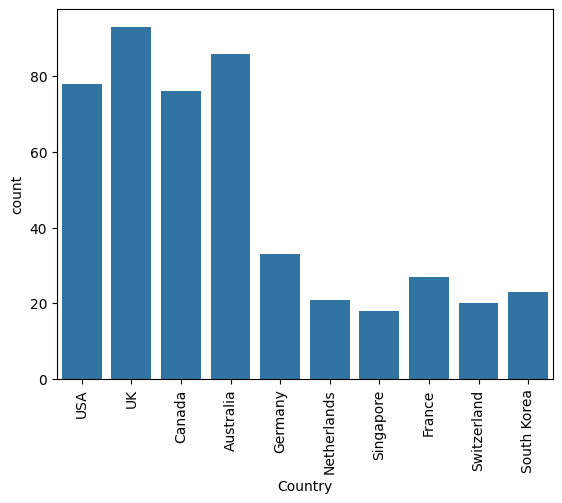

In [35]:
sns.countplot(data=country, x='Country');
plt.xticks(rotation='vertical')
plt.show()

In [36]:
df['City'].value_counts().head()

City
Singapore    18
Sydney       11
Melbourne    11
London       10
Canberra      8
Name: count, dtype: int64

In [37]:
city=df[df['City'].isin(['Singapore', 'Sydney', 'Melbourne', 'London', 'Canberra'])]

In [38]:
city['City'].value_counts()

City
Singapore    18
Sydney       11
Melbourne    11
London       10
Canberra      8
Name: count, dtype: int64

In [39]:
city.shape

(58, 12)

<Axes: xlabel='Level', ylabel='count'>

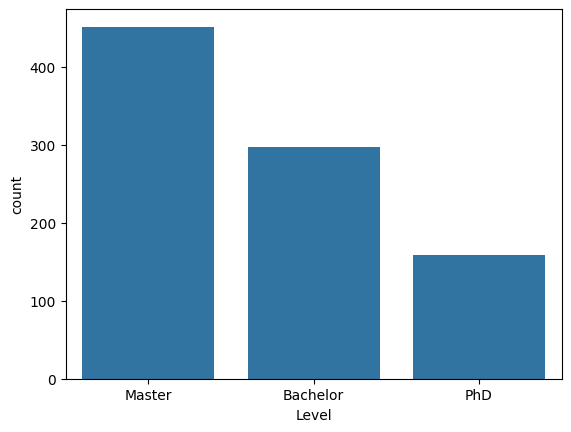

In [40]:
sns.countplot(data=df, x='Level')

In [41]:
df['Duration_Years'].value_counts()

Duration_Years
2.0    423
4.0    276
3.0    171
5.0     17
1.0     16
2.5      3
1.5      1
Name: count, dtype: int64

In [42]:
df[df['Duration_Years']==1.5]

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
7,Singapore,Singapore,National University of Singapore,Finance,Master,1.5,35000,81.1,1900,90,800,1.34


In [43]:
d1=df[df['Level'] == 'Master'].head(150)

d2=df[df['Level'] == 'Bachelor'].head(150)

d3=df[df['Level'] == 'PhD'].head(150)

In [44]:
d2

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
15,South Korea,Busan,Pusan National University,Business,Bachelor,4.0,5900,62.4,700,130,500,1320.50
16,New Zealand,Auckland,University of Auckland,Marine Biology,Bachelor,3.0,28500,69.8,1200,245,600,1.64
17,Austria,Vienna,University of Vienna,Social Sciences,Bachelor,3.0,1500,67.4,950,160,500,0.92
18,Belgium,Brussels,KU Leuven,Biomedical Sciences,Bachelor,3.0,3500,68.9,1000,180,550,0.92
19,USA,Ann Arbor,University of Michigan,Aerospace Engineering,Bachelor,4.0,52300,72.5,1800,160,1500,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...
279,UK,Oxford Brookes,Oxford Brookes University,Computer Science,Bachelor,3.0,19900,77.8,1500,490,800,0.79
280,UK,De Montfort,De Montfort University,Computer Science,Bachelor,3.0,19600,68.9,900,490,800,0.79
281,UK,Westminster,University of Westminster,Computer Science,Bachelor,3.0,19300,83.2,1800,490,800,0.79
282,UK,Greenwich,University of Greenwich,Computer Science,Bachelor,3.0,19000,83.2,1700,490,800,0.79


In [45]:
d4=pd.concat([d1, d2, d3])

In [46]:
d4.shape

(450, 12)

<Axes: xlabel='Duration_Years', ylabel='Count'>

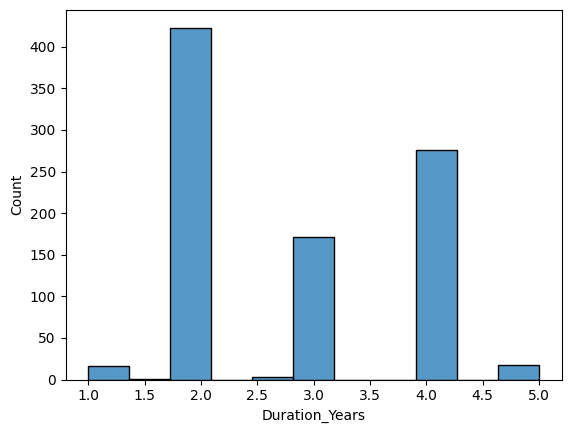

In [47]:
sns.histplot(data=df, x='Duration_Years')

<Axes: xlabel='Duration_Years', ylabel='Count'>

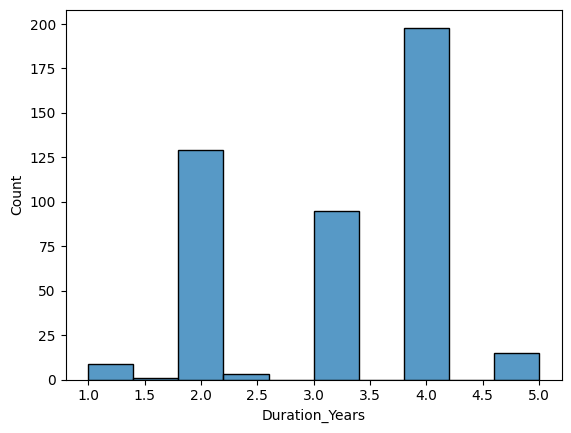

In [48]:
sns.histplot(data=d4, x='Duration_Years')

In [49]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='object')

<Axes: xlabel='Tuition_USD', ylabel='Count'>

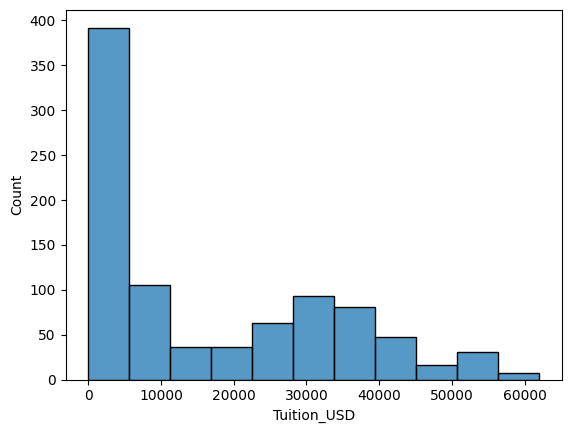

In [50]:
sns.histplot(data=df, x='Tuition_USD')

<Axes: xlabel='Rent_USD', ylabel='Count'>

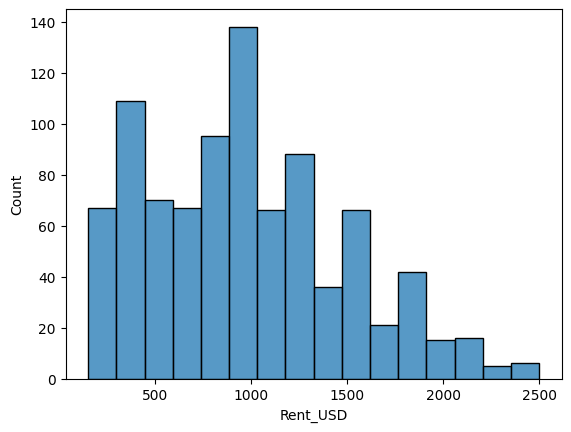

In [51]:
sns.histplot(data=df, x='Rent_USD')

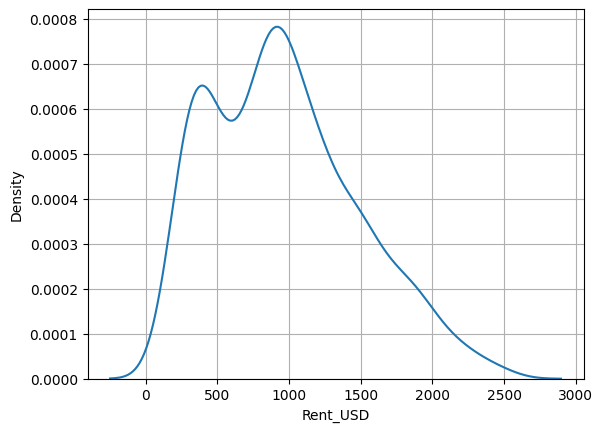

In [52]:
sns.kdeplot(data=df, x='Rent_USD')
plt.grid()

In [53]:
df['University'].value_counts().head(10)

University
University of Washington           6
Stanford University                5
Australian National University     5
University of Tasmania             5
University of Western Australia    5
University of Adelaide             5
Griffith University                5
University of Sydney               5
University of Melbourne            5
University of Wollongong           5
Name: count, dtype: int64

In [54]:
university=df[df['University'].isin([
  'University of Washington',
  'Stanford University',
  'Australian National University',
  'University of Tasmania',
  'University of Western Australia',
  'University of Adelaide',
  'Griffith University',
  'University of Sydney',
  'University of Melbourne',
  'University of Wollongong'
  ])]

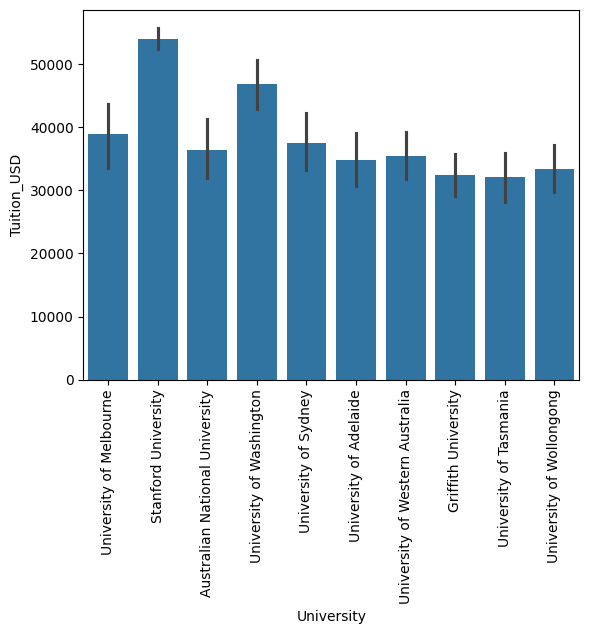

In [55]:
sns.barplot(data=university, x='University', y='Tuition_USD')
plt.xticks(rotation='vertical')
plt.show()

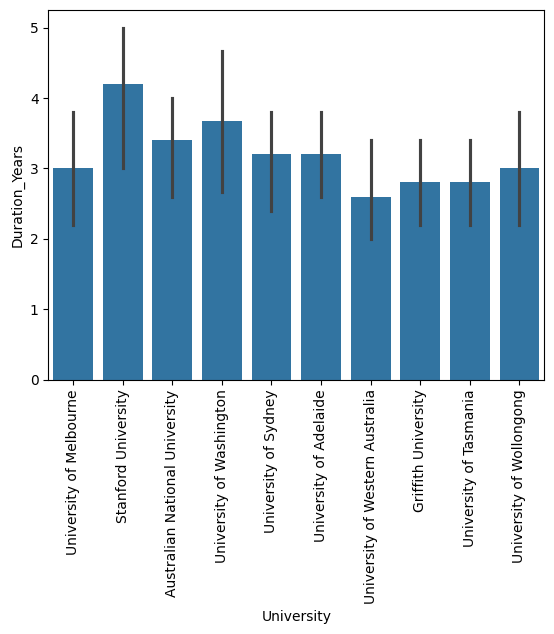

In [56]:
sns.barplot(data=university, x='University', y='Duration_Years')
plt.xticks(rotation='vertical')
plt.show()

<Axes: xlabel='Duration_Years', ylabel='Tuition_USD'>

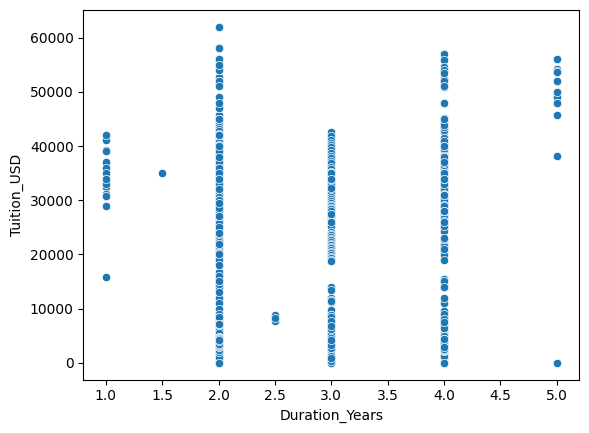

In [57]:
sns.scatterplot(data=df, x='Duration_Years', y='Tuition_USD')

In [58]:
## Top 10 countriies -- Top 10 universities -- Totuion Fees

In [59]:
country['University'].value_counts().head(10)

University
University of Washington           6
Stanford University                5
Griffith University                5
University of Western Australia    5
University of Adelaide             5
University of Tasmania             5
University of Newcastle            5
Australian National University     5
University of Wollongong           5
University of Sydney               5
Name: count, dtype: int64

In [60]:
university2=country[country['University'].isin([
  'University of Washington',
  'Stanford University',
  'Australian National University',
  'University of Tasmania',
  'University of Western Australia',
  'University of Adelaide',
  'Griffith University',
  'University of Sydney',
  'University of Wollongong',
  'University of Newcastle'
  ])]

In [61]:
# Pivot table -- filtered table

data=university2.pivot_table(index='Country', columns='University', values='Tuition_USD', aggfunc='mean')

<Axes: xlabel='University', ylabel='Country'>

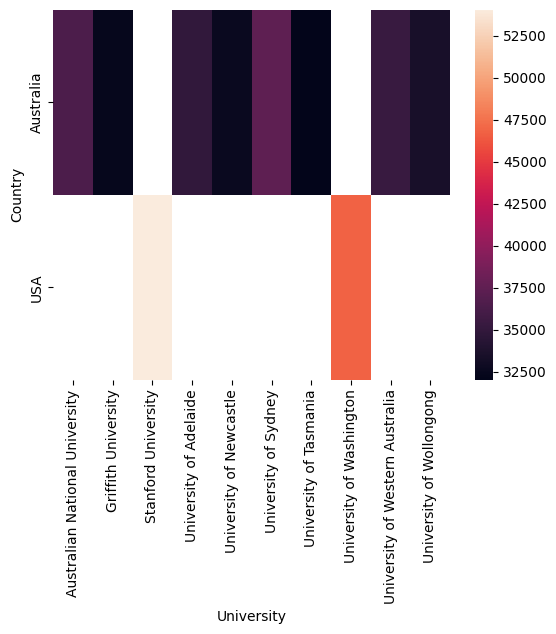

In [62]:
sns.heatmap(data)

5. Feature Engineering and Model Building

In [63]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='object')

In [64]:
df['Total_Cost'] = df['Tuition_USD'] + df['Rent_USD']

In [65]:
df

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate,Total_Cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,4000,70.2,1000,99,850,0.92,5000
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,6800,50.5,400,120,400,4.65,7200
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,4200,64.2,600,200,800,3.75,4800
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,50000,77.8,2000,160,1500,1.00,52000


In [66]:
## Feature Selection

In [67]:
df5=df[['Country',	'City',	'University',	'Program'	,'Level'	,'Duration_Years',	'Tuition_USD'	,'Living_Cost_Index',	'Rent_USD'	,'Visa_Fee_USD'	,'Insurance_USD'	,	'Total_Cost']]

In [68]:
df5.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Total_Cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,1600


In [69]:
## Label encoding

In [70]:
from sklearn.preprocessing import LabelEncoder;
from sklearn.preprocessing import OrdinalEncoder;
from sklearn.preprocessing import OneHotEncoder;

In [71]:
le=LabelEncoder()

In [73]:
df['Country']=le.fit_transform(df['Country'])

In [74]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate,Total_Cost
0,66,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00,57600
1,65,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79,43000
2,9,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35,40100
3,2,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52,43400
4,22,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92,1600


In [75]:
df['City']=le.fit_transform(df['City'])

In [77]:
df['University']=le.fit_transform(df['University'])
df['Program']=le.fit_transform(df['Program'])
df['Level']=le.fit_transform(df['Level'])

In [78]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate,Total_Cost
0,66,84,101,17,1,2.0,55400,83.5,2200,160,1500,1.00,57600
1,65,283,128,27,1,1.0,41200,75.8,1800,485,800,0.79,43000
2,9,503,572,9,1,2.0,38500,72.5,1600,235,900,1.35,40100
3,2,313,495,44,1,2.0,42000,71.2,1400,450,650,1.52,43400
4,22,330,307,66,1,2.0,500,70.5,1100,75,550,0.92,1600


In [79]:
## Now seperate input data and output data

In [80]:
df=df[['Country',	'City',	'University',	'Program'	,'Level'	,'Duration_Years',	'Tuition_USD'	,'Living_Cost_Index',	'Rent_USD'	,'Visa_Fee_USD'	,'Insurance_USD'	,	'Total_Cost']]

In [81]:
df.head()

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Total_Cost
0,66,84,101,17,1,2.0,55400,83.5,2200,160,1500,57600
1,65,283,128,27,1,1.0,41200,75.8,1800,485,800,43000
2,9,503,572,9,1,2.0,38500,72.5,1600,235,900,40100
3,2,313,495,44,1,2.0,42000,71.2,1400,450,650,43400
4,22,330,307,66,1,2.0,500,70.5,1100,75,550,1600


In [82]:
X=df.iloc[:, :9]
Y=df['Total_Cost']

In [83]:
X

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD
0,66,84,101,17,1,2.0,55400,83.5,2200
1,65,283,128,27,1,1.0,41200,75.8,1800
2,9,503,572,9,1,2.0,38500,72.5,1600
3,2,313,495,44,1,2.0,42000,71.2,1400
4,22,330,307,66,1,2.0,500,70.5,1100
...,...,...,...,...,...,...,...,...,...
902,21,469,556,25,1,2.0,4000,70.2,1000
903,38,344,345,17,0,3.0,6800,50.5,400
904,51,12,154,57,1,2.0,4200,64.2,600
905,66,441,585,84,2,5.0,50000,77.8,2000


In [84]:
Y

0      57600
1      43000
2      40100
3      43400
4       1600
       ...  
902     5000
903     7200
904     4800
905    52000
906    34800
Name: Total_Cost, Length: 907, dtype: int32

In [88]:
# Feature scalling -- all the value in similar range of 0 to 1
# two ways - normalization and Standardization

In [89]:
from sklearn.preprocessing import StandardScaler

In [90]:
ss=StandardScaler()

In [91]:
X=ss.fit_transform(X)

In [92]:
X

array([[ 1.29937861, -1.18314994, -1.25623694, ...,  2.33478669,
         1.35689951,  2.38124638],
       [ 1.25678296,  0.02539721, -1.10697039, ...,  1.47798387,
         0.80880148,  1.60735677],
       [-1.12857335,  1.3614795 ,  1.3476352 , ...,  1.31507066,
         0.57390232,  1.22041197],
       ...,
       [ 0.66044389, -1.62041323, -0.96323222, ..., -0.75453052,
        -0.01690464, -0.71431206],
       [ 1.29937861,  0.98494722,  1.41950429, ...,  2.00896026,
         0.9511646 ,  1.99430158],
       [ 1.25678296,  0.4140757 ,  1.01593175, ...,  1.04354864,
        -0.23044933, -0.32736725]], shape=(907, 9))

In [93]:
# Train Test splitting
#   training = 80% and testing = 20%

In [94]:
from sklearn.model_selection import train_test_split

In [95]:
x_train, x_test, y_train, y_test=train_test_split(X,Y, test_size=0.2, random_state=42)

In [98]:
x_test.shape

(182, 9)

In [99]:
x_train.shape

(725, 9)

In [100]:
y_test.shape

(182,)

In [101]:
y_train.shape

(725,)

In [102]:
# data prepation is done until now.
#  now will build ML model (model training and evaluation)

### Regression
1. linear regression

In [103]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [104]:
lr.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [106]:
y_predict=lr.predict(x_test)

In [107]:
# Evalution Matrics
from sklearn.metrics import mean_absolute_error

In [108]:
mean_absolute_error(y_test, y_predict)

1.2353136828476256e-11

In [110]:
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test, y_predict)

2.3357398923255605e-22

In [113]:
# Ridge
from sklearn.linear_model import Ridge
r=Ridge(alpha=1.0)


In [114]:
r.fit(x_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [115]:
y_predict=r.predict(x_test)

In [116]:
mean_absolute_error(y_test, y_predict)

30.712935282906674

In [117]:
# Laso

from sklearn.linear_model import Lasso
l=Lasso()

In [118]:
l.fit(x_train, y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [119]:
y_predict=l.predict(x_test)

In [120]:
mean_absolute_error(y_test, y_predict)

2.3693598281139243

4. ElasticNet Algorithm
5. DescisionTree Regressor - imported from sklearn.tree
6. RandomForest Regressor (ensemble learning -- combination of multiple algorithms)
    imported from sklearn.ensemble
7. 

In [126]:

from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor(n_estimators=100)

In [127]:
forest.fit(x_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [128]:
y_predict=forest.predict(x_test)

In [129]:
mean_absolute_error(y_test, y_predict)

148.79395604395606

In [125]:
### Bagging Regressor -- ensemble learning

In [130]:
from sklearn.ensemble import BaggingRegressor

In [135]:
bag=BaggingRegressor(n_estimators=100)


In [136]:
bag.fit(x_train, y_train)

,estimator,None
,n_estimators,100
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,False
,warm_start,False
,n_jobs,None
,random_state,None
,verbose,0


In [137]:
y_predict=bag.predict(x_test)

In [138]:
mean_absolute_error(y_test, y_predict)

150.50274725274727

In [ ]:
### Stacking Regressor

6. Classification

In [140]:
st=pd.read_csv("Student Depression Dataset.csv")

In [141]:
st.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


In [142]:
st.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

In [143]:
st.columns

Index(['id', 'Gender', 'Age', 'City', 'Profession', 'Academic Pressure',
       'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?', 'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression'],
      dtype='object')

In [144]:
# Feature selection
st=st[['Gender', 'Age', 'City', 'Profession', 'Academic Pressure',
        'CGPA', 'Study Satisfaction', 
       'Sleep Duration', 'Dietary Habits', 'Degree',
        'Work/Study Hours',
       'Financial Stress', 'Family History of Mental Illness', 'Depression']]

In [145]:
# label encoding

In [146]:
from sklearn.preprocessing import LabelEncoder

le= LabelEncoder()

In [147]:
st['Gender']=le.fit_transform(st['Gender']);
st['City']=le.fit_transform(st['City']);
st['Profession']=le.fit_transform(st['Profession']);
st['Sleep Duration']=le.fit_transform(st['Sleep Duration']);
st['Dietary Habits']=le.fit_transform(st['Dietary Habits']);
st['Family History of Mental Illness']=le.fit_transform(st['Family History of Mental Illness']);

In [148]:
st.head()

,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,33.0,51,11,5.0,8.97,2.0,0,0,B.Pharm,3.0,1.0,0,1
1,0,24.0,3,11,2.0,5.90,5.0,0,1,BSc,3.0,2.0,1,0
2,1,31.0,44,11,3.0,7.03,5.0,2,0,BA,9.0,1.0,1,0
3,0,28.0,49,11,3.0,5.59,2.0,1,1,BCA,4.0,5.0,1,1
4,0,25.0,16,11,4.0,8.13,3.0,0,1,M.Tech,1.0,1.0,0,0


In [149]:
st['Degree']=le.fit_transform(st['Degree']);
st['Financial Stress']=st['Financial Stress'].astype('float32');

In [150]:
st['Financial Stress'].value_counts()

Financial Stress
5.0    6715
4.0    5775
3.0    5226
1.0    5121
2.0    5061
Name: count, dtype: int64

In [151]:
st.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 14 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Gender                            27901 non-null  int64  
 1   Age                               27901 non-null  float64
 2   City                              27901 non-null  int64  
 3   Profession                        27901 non-null  int64  
 4   Academic Pressure                 27901 non-null  float64
 5   CGPA                              27901 non-null  float64
 6   Study Satisfaction                27901 non-null  float64
 7   Sleep Duration                    27901 non-null  int64  
 8   Dietary Habits                    27901 non-null  int64  
 9   Degree                            27901 non-null  int64  
 10  Work/Study Hours                  27901 non-null  float64
 11  Financial Stress                  27898 non-null  float32
 12  Fami

In [152]:
# Seperating input and output data

In [153]:
st.columns

Index(['Gender', 'Age', 'City', 'Profession', 'Academic Pressure', 'CGPA',
       'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree',
       'Work/Study Hours', 'Financial Stress',
       'Family History of Mental Illness', 'Depression'],
      dtype='object')

In [191]:
X=st[['Gender', 'Age', 'City', 'Profession', 'Academic Pressure', 'CGPA',
       'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree',
       'Work/Study Hours', 'Financial Stress',
       'Family History of Mental Illness']];
Y=st['Depression']

In [196]:
X

,Gender,Age,City,Profession,Academic Pressure,CGPA,Study Satisfaction,Sleep Duration,Dietary Habits,Degree,Work/Study Hours,Financial Stress,Family History of Mental Illness
0,1,33.0,51,11,5.0,8.97,2.0,0,0,3,3.0,1.0,0
1,0,24.0,3,11,2.0,5.90,5.0,0,1,10,3.0,2.0,1
2,1,31.0,44,11,3.0,7.03,5.0,2,0,5,9.0,1.0,1
3,0,28.0,49,11,3.0,5.59,2.0,1,1,7,4.0,5.0,1
4,0,25.0,16,11,4.0,8.13,3.0,0,1,17,1.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
27896,0,27.0,45,11,5.0,5.75,5.0,0,3,11,7.0,1.0,1
27897,1,27.0,25,11,2.0,9.40,3.0,2,0,25,0.0,3.0,1
27898,1,31.0,9,11,3.0,6.61,4.0,0,3,22,12.0,2.0,0
27899,0,18.0,25,11,5.0,6.88,2.0,2,0,11,10.0,5.0,0


In [155]:
# feature scalling step

In [156]:
from sklearn.preprocessing import StandardScaler
s=StandardScaler()

In [197]:
X=s.fit_transform(X)

In [199]:
X

array([[ 0.89137266,  1.46320131,  1.51052261, ..., -1.12111524,
        -1.48878834, -0.96838258],
       [-1.12186524, -0.37145045, -1.42420578, ..., -1.12111524,
        -0.79304951,  1.03264972],
       [ 0.89137266,  1.05550092,  1.08254139, ...,  0.49721209,
        -1.48878834,  1.03264972],
       ...,
       [ 0.89137266,  1.05550092, -1.05736473, ...,  1.30637576,
        -0.79304951, -0.96838258],
       [-1.12186524, -1.59455162, -0.07912193, ...,  0.76693332,
         1.29416701, -0.96838258],
       [ 0.89137266,  0.24010013,  0.71570034, ..., -1.39083646,
        -0.09731067,  1.03264972]], shape=(27898, 13))

In [198]:
Y

0        1
1        0
2        0
3        1
4        0
        ..
27896    0
27897    0
27898    0
27899    1
27900    1
Name: Depression, Length: 27898, dtype: int64

In [160]:
# Train test split

In [161]:
from sklearn.model_selection import train_test_split

In [200]:
xTrain, xTest, yTrian, ytest = train_test_split(X,Y, test_size=0.2, random_state=42)

In [201]:
xTest.shape

(5580, 13)

In [202]:
ytest.shape

(5580,)

In [203]:
yTrian.shape

(22318,)

In [204]:
xTrain

array([[ 0.89137266,  1.6670515 ,  1.08254139, ...,  0.49721209,
        -1.48878834, -0.96838258],
       [ 0.89137266, -0.57530065,  0.71570034, ...,  0.76693332,
        -0.09731067,  1.03264972],
       [-1.12186524, -0.16760026, -0.50710316, ...,  1.03665454,
         0.59842817,  1.03264972],
       ...,
       [ 0.89137266, -1.59455162, -0.32368263, ..., -0.31195157,
         1.29416701,  1.03264972],
       [ 0.89137266,  0.64780053,  0.65456016, ...,  0.76693332,
         1.29416701, -0.96838258],
       [-1.12186524, -0.57530065,  1.08254139, ...,  0.22749087,
         1.29416701,  1.03264972]], shape=(22318, 13))

In [167]:
## Logistic Regression

In [168]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()

In [205]:
lr.fit(xTrain, yTrian)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [206]:
yPredict=lr.predict(xTest)

In [207]:
from sklearn.metrics import accuracy_score

In [208]:
accuracy_score(ytest, yPredict)

0.7946236559139785

In [209]:
# Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

tree=DecisionTreeClassifier(max_depth=5)

In [210]:
tree.fit(xTrain,yTrian)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [211]:
yPredict=tree.predict(xTest)

In [212]:
accuracy_score(ytest, yPredict)

0.7630824372759857

In [213]:
from sklearn.ensemble import RandomForestClassifier
forest = RandomForestClassifier(n_estimators=100)

In [214]:
forest.fit(xTrain,yTrian)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [215]:
yPredict=forest.predict(xTest)

In [216]:
accuracy_score(ytest, yPredict)

0.7896057347670251

In [218]:
## XGBClassifier, AdaBoostClassifier, CatBoostClassifier, KNeighbors Classifier

In [219]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

In [220]:
knn.fit(xTrain, yTrian)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [221]:
yPredict=knn.predict(xTest)

In [222]:
accuracy_score(ytest, yPredict)

0.7530465949820788

In [223]:
## Support vector classification

In [224]:
# Naive Nayes --
#   Bernoulli Naive
#   MultiNominal Naive

In [225]:
# Stacking Classifier

In [228]:
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier


In [231]:
estimators=[('rf', RandomForestClassifier()), ('bc', BaggingClassifier())]

stack=StackingClassifier(estimators=estimators, final_estimator=AdaBoostClassifier())

In [232]:
stack.fit(xTrain, yTrian)

,estimators,"[('rf', ...), ('bc', ...)]"
,final_estimator,AdaBoostClassifier()
,cv,None
,stack_method,'auto'
,n_jobs,None
,passthrough,False
,verbose,0
,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2


In [233]:
yPredict=stack.predict(xTest)

In [234]:
accuracy_score(ytest, yPredict)

0.792831541218638

In [ ]:
# Hyper parameter tuning

# paramgride={'n_estimators': [100,200], 'max_depth': [4,6,8]}

In [237]:
from sklearn.model_selection import GridSearchCV

paramgride={'n_estimators': [100,200], 'max_depth': [4,6,8]}

grid = GridSearchCV(RandomForestRegressor(), param_grid=paramgride, cv=5)

In [238]:
grid.fit(x_train, y_train)

,estimator,RandomForestRegressor()
,param_grid,"{'max_depth': [4, 6, ...], 'n_estimators': [100, 200]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [239]:
print(grid.best_params_)
print(grid.best_score_)

{'max_depth': 8, 'n_estimators': 100}
0.9997385996616691


In [244]:
from sklearn.ensemble import RandomForestRegressor

model=RandomForestRegressor(n_estimators=200)

In [245]:
model.fit(x_train, y_train)

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [246]:
y_predict=model.predict(x_test)

In [247]:
mean_absolute_error(y_test, y_predict)

149.5173076923077

In [248]:
# to deploy our model we convert model to file we use pickle

In [249]:
import pickle



In [250]:
with open('model.pkl', 'wb') as file:
  pickle.dump(model, file)

In [251]:
with open('model.pkl', 'rb') as file:
  new_model=pickle.load(file)

In [252]:
new_model

,n_estimators,200
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False
